
# Yoga Posture Detection - Transfer Learning
This notebook implements a Transfer Learning approach for Yoga Posture Detection based on a two-phase training blueprint:
1.  **Load and Freeze Base Model** (MobileNetV2 acting as a feature extractor).
2.  **Build Custom Classification Head** (with heavy Dropout and BatchNormalization).
3.  **Train in Two Phases** (Feature Extraction followed by Fine-Tuning).
4.  **Data Augmentation** (handling < 100 images per class).


In [1]:

import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout, BatchNormalization
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import time

print("TensorFlow Version:", tf.__version__)


Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\ABHIROOP\\.matplotlib\\fontlist-v390.json.matplotlib-lock'


TensorFlow Version: 2.20.0



## 1. Data Setup & Augmentation (Step 4 of Blueprint)
We load the dataset and apply data augmentation (flips, rotations, zoom) to prevent overfitting on our limited images.


In [2]:

dataset_dir = r"d:\Yoga Website\Dataset"

classes = [d for d in os.listdir(dataset_dir) if os.path.isdir(os.path.join(dataset_dir, d))]
classes.sort()

filepaths = []
labels = []
for c in classes:
    class_dir = os.path.join(dataset_dir, c)
    images = glob.glob(os.path.join(class_dir, "*.jpg")) + glob.glob(os.path.join(class_dir, "*.png")) + glob.glob(os.path.join(class_dir, "*.jpeg"))
    for img in images:
        filepaths.append(img)
        labels.append(c)

df = pd.DataFrame({'filepath': filepaths, 'label': labels})

# Split: 80% Train, 20% Val
train_df, val_df = train_test_split(df, test_size=0.20, random_state=42, stratify=df['label'])

BATCH_SIZE = 32
IMG_SIZE = (224, 224)

# Data Augmentation Setup
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,       # rotate slightly
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.2,          # adjust zoom
    horizontal_flip=True,    # randomly flip horizontally
    fill_mode='nearest'
)

val_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col='filepath',
    y_col='label',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True
)

val_generator = val_datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col='filepath',
    y_col='label',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

num_classes = len(train_generator.class_indices)
print(f"Number of actual target classes found: {num_classes}")


Found 2204 validated image filenames belonging to 47 classes.
Found 552 validated image filenames belonging to 47 classes.
Number of actual target classes found: 47



## 2. Load Base Model and Build Custom Head (Steps 1 & 2 of Blueprint)
We load MobileNetV2 without the top layer and freeze it. Then, we attach a custom classification head with BatchNormalization and heavy Dropout.


In [3]:

print("Loading Base Model...")
# 1. Load and Freeze the Base Model
base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base_model.trainable = False # Freeze base

# 2. Build the Custom Classification Head
x = base_model.output
x = GlobalAveragePooling2D()(x) # Flatten spatial dimensions
x = Dense(512, activation='relu')(x)
x = BatchNormalization()(x)     # Apply BatchNormalization
x = Dropout(0.5)(x)             # Heavy Dropout (0.5)

# Final output layer
predictions = Dense(num_classes, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=predictions)

# Callbacks
callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=1e-6)
]


Loading Base Model...



## 3. Training Phase 1 (Feature Extraction)
Train only the new custom head while the base model acts as an intelligent feature extractor.


Starting Phase 1: Feature Extraction...


c:\Users\ABHIROOP\anaconda3\envs\chatbot\lib\site-packages\PIL\Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 1/15
69/69 ━━━━━━━━━━━━━━━━━━━━ 76s 977ms/step - accuracy: 0.2405 - loss: 3.2328 - val_accuracy: 0.4438 - val_loss: 1.9974 - learning_rate: 0.0010
Epoch 2/15
69/69 ━━━━━━━━━━━━━━━━━━━━ 107s 1s/step - accuracy: 0.5200 - loss: 1.7129 - val_accuracy: 0.5688 - val_loss: 1.5084 - learning_rate: 0.0010
Epoch 3/15
69/69 ━━━━━━━━━━━━━━━━━━━━ 89s 1s/step - accuracy: 0.6402 - loss: 1.2709 - val_accuracy: 0.6431 - val_loss: 1.2932 - learning_rate: 0.0010
Epoch 4/15
69/69 ━━━━━━━━━━━━━━━━━━━━ 60s 866ms/step - accuracy: 0.6792 - loss: 1.1039 - val_accuracy: 0.6359 - val_loss: 1.2432 - learning_rate: 0.0010
Epoch 5/15
69/69 ━━━━━━━━━━━━━━━━━━━━ 154s 2s/step - accuracy: 0.7314 - loss: 0.9357 - val_accuracy: 0.6467 - val_loss: 1.1775 - learning_rate: 0.0010
Epoch 6/15
69/69 ━━━━━━━━━━━━━━━━━━━━ 138s 2s/step - accuracy: 0.7550 - loss: 0.8403 - val_accuracy: 0.6522 - val_loss: 1.1795 - learning_rate: 0.0010
Epoch 7/15
69/69 ━━━━━━━━━━━━━━━━━━━━ 119s 2s/step - accuracy: 0.7745 - loss: 0.7594 - val_

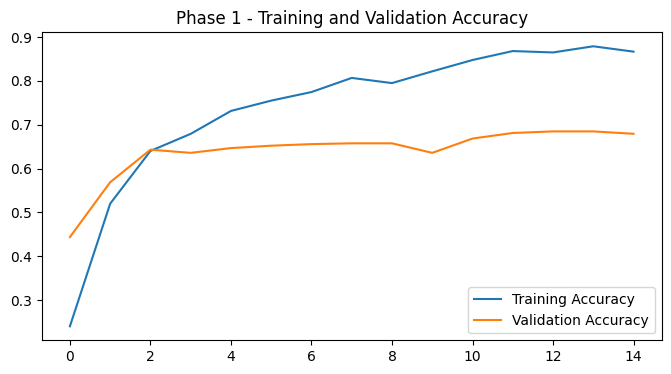

In [4]:

# Compile Model for Phase 1
model.compile(optimizer=Adam(learning_rate=0.001), loss='categorical_crossentropy', metrics=['accuracy'])

print("Starting Phase 1: Feature Extraction...")
history_phase1 = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=15, 
    callbacks=callbacks,
    verbose=1
)

# Plot Phase 1 History
acc = history_phase1.history['accuracy']
val_acc = history_phase1.history['val_accuracy']
plt.figure(figsize=(8, 4))
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Phase 1 - Training and Validation Accuracy')
plt.show()



## 4. Training Phase 2 (Fine-Tuning)
Unfreeze the top layers of the base model and train with a very small learning rate to specialize the feature maps.


Starting Phase 2: Fine-Tuning...
Epoch 1/15
69/69 ━━━━━━━━━━━━━━━━━━━━ 153s 2s/step - accuracy: 0.7137 - loss: 0.9575 - val_accuracy: 0.6649 - val_loss: 1.0593 - learning_rate: 1.0000e-05
Epoch 2/15
69/69 ━━━━━━━━━━━━━━━━━━━━ 132s 2s/step - accuracy: 0.7473 - loss: 0.8341 - val_accuracy: 0.6467 - val_loss: 1.1269 - learning_rate: 1.0000e-05
Epoch 3/15
69/69 ━━━━━━━━━━━━━━━━━━━━ 130s 2s/step - accuracy: 0.7672 - loss: 0.7434 - val_accuracy: 0.6576 - val_loss: 1.1635 - learning_rate: 1.0000e-05
Epoch 4/15
69/69 ━━━━━━━━━━━━━━━━━━━━ 132s 2s/step - accuracy: 0.7663 - loss: 0.7461 - val_accuracy: 0.6540 - val_loss: 1.1746 - learning_rate: 2.0000e-06
Epoch 5/15
69/69 ━━━━━━━━━━━━━━━━━━━━ 133s 2s/step - accuracy: 0.7700 - loss: 0.7396 - val_accuracy: 0.6486 - val_loss: 1.1691 - learning_rate: 2.0000e-06


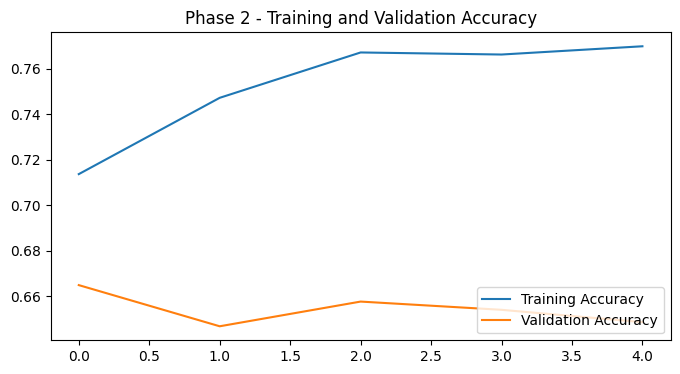

Model saved as transfer_learning_yoga_final.h5


In [5]:

# Unfreeze the base model
base_model.trainable = True

# Let's say we freeze all layers except the last 20 layers for fine-tuning
for layer in base_model.layers[:-20]:
    layer.trainable = False

# Recompile with very small learning rate (e.g., 1e-5)
model.compile(optimizer=Adam(learning_rate=1e-5), loss='categorical_crossentropy', metrics=['accuracy'])

print("Starting Phase 2: Fine-Tuning...")
history_phase2 = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=15, 
    callbacks=callbacks,
    verbose=1
)

# Plot Phase 2 History
acc = history_phase2.history['accuracy']
val_acc = history_phase2.history['val_accuracy']
plt.figure(figsize=(8, 4))
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Phase 2 - Training and Validation Accuracy')
plt.show()

# Save the final fine-tuned model
model.save('transfer_learning_yoga_final.h5')
print("Model saved as transfer_learning_yoga_final.h5")
